# Czy te nagrania nadają się do analizy?
**Zacznij tutaj.** Wybierz kernel `.venv` i kliknij **Run All**. Oryginały są w `assets/1-batch-ping` i `assets/2-batch-ok`.
Notebook sprawdza pliki, wykrywa uderzenia i daje odsłuch z wykresami. Nie zmienia źródłowego audio.

Wniosek: impulsy nadają się do eksploracji. Trzeba wyjaśnić wyciszanie tła, ujednolicić zapis i wydłużyć przerwy przed oceną pełnego wybrzmienia. Dwie NOK i roboczo trzy OK to nadal pięć obiektów.

In [1]:
from pathlib import Path
import sys, json, io, contextlib
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config/client_archive_manifest.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Otwórz folder ceramic-ping-lab w VS Code.")
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from pinglab.clientstudy import prepare, load, embeddings, recording_widget, OUT_REL
OUT = ROOT / OUT_REL
pd.set_option("display.max_colwidth", 65)
%matplotlib inline
print("Python:", sys.executable)
print("Wyniki:", OUT)


Python: /Users/karolsii/dev/ceramic-ping-lab/.venv/bin/python
Wyniki: /Users/karolsii/dev/ceramic-ping-lab/reports/runs/client-combined-20260929


## 1. Wczytanie obu paczek
Cache przyspiesza kolejne uruchomienia; jego klucz zależy od SHA256 audio i wersji ekstrakcji. Zmień `FORCE = True`, aby przeliczyć cechy od początku.

In [2]:
FORCE = False
with contextlib.redirect_stdout(io.StringIO()):
    recordings, candidates, features = prepare(ROOT, force=FORCE)
from pinglab.clientdiagnostics import figures
facts = figures(ROOT)
display(pd.DataFrame([facts]).T.rename(columns={0:"Wartość"}))
display(recordings.groupby(["batch","scope"]).agg(pliki=("recording_id","size"), sekundy=("duration_s","sum"), kandydaci=("n_accepted","sum")).round(2))

,Wartość
audio_files,45
duration_s,1184.492
accepted_candidates,3613
core_files,27
core_candidates,2621
n_files_zero_run_100ms,17
n_ok_files_zero_run_100ms,10
all_dual_mono,True
max_clip_fraction,0.0
median_file_gap_s,0.28


pliki  sekundy  kandydaci
batch        scope                                 
1-batch-ping background       1    31.59          0
             chipped          6   211.52        725
             core             9   376.73       1316
             old_unknown      8   124.71        267
2-batch-ok   core            21   439.93       1305

## 2. Co wymaga wyjaśnienia
**Ciąg zer >100 ms** to powód do sprawdzenia toru pomiarowego. Pojedyncze zera w WAV 16-bit mogą wynikać z kwantyzacji. Nie nazywamy każdego zera odszumianiem. Trzy pliki krótsze niż 2 s zachowujemy w spisie, lecz nie uczymy na nich modeli.

,recording_id,filename,duration_s,longest_zero_s,below_minus100_fraction,n_accepted
1,R02,Bad 1/NOK Normal HITS on 4 point support.m4a,36.224,0.384,0.028,126
4,R05,Bad 2/NOK 4 point support tool change.m4a,40.384,1.557,0.048,147
6,R07,Bad 2/NOK Knocking around crack from 14 to 22 sec.wav,48.190,0.136,0.006,157
15,R16,FACTORY DIRTY NOISE.m4a,31.595,4.160,0.229,0
18,R19,OLD/NOK all hits 1.m4a,12.843,0.213,0.062,20
22,R23,OLD/Ok all hits 1.m4a,14.763,0.213,0.069,20
23,R24,OLD/Ok all hits 2.m4a,15.061,0.491,0.203,20
27,G04,OK 4 point support 2.wav,29.890,0.672,0.046,97
28,G05,OK 4 point support 3.wav,30.600,0.500,0.040,98
29,G06,OK 4 point support.wav,33.450,0.856,0.056,109


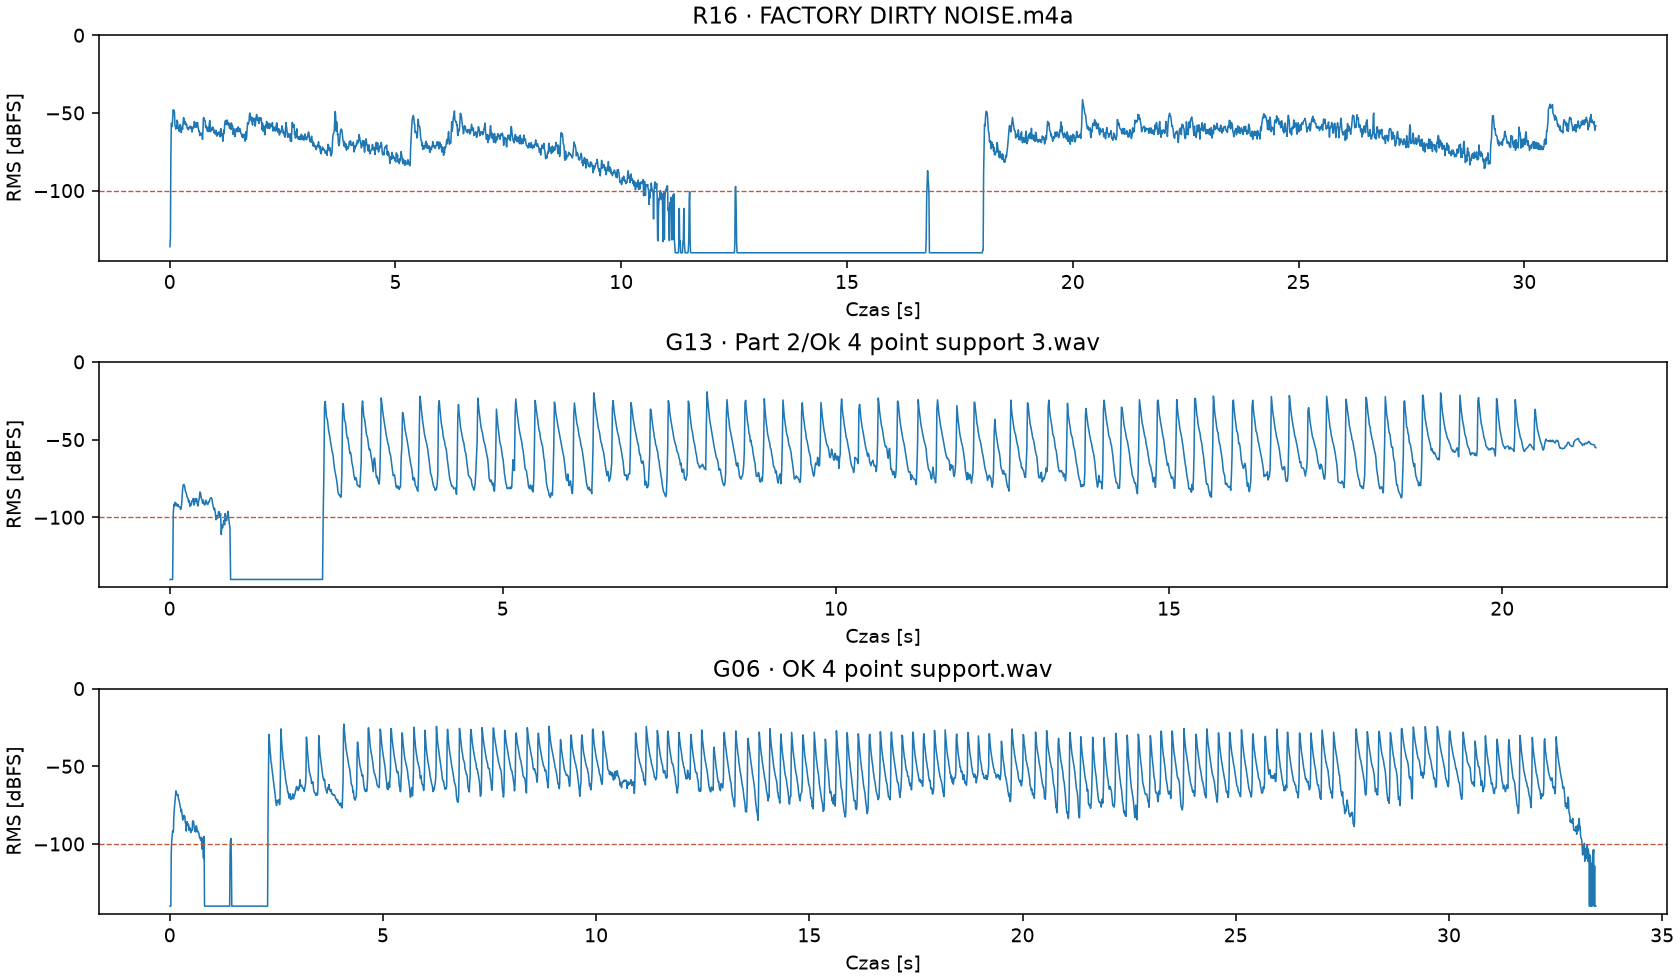

In [3]:
display(recordings.loc[(recordings.longest_zero_s > .1) | (recordings.duration_s < 2),
    ["recording_id","filename","duration_s","longest_zero_s","below_minus100_fraction","n_accepted"]].round(3))
display(Image(filename=str(OUT / "figures/quiet_intervals.png")))

## 3. Klikalny odsłuch, segmentacja i spektrogram
Wybierz plik, początek i długość fragmentu. Zielone pola to **stałe okna cech 20 ms przed +150 ms po początku**. Złote linie oznaczają wykrycia odrzucone przez reguły jakości. To nie pomiar fizycznego końca wybrzmienia. Audio zachowuje poziom źródłowy; może być ciche.

In [4]:
controls = recording_widget(ROOT)

## 4. Czy detektor widzi pojedyncze uderzenia?
Niżej te same reguły dla kilku OK i NOK oraz krótkiego G11. Detektor nie wymusza zadanej liczby trafień. Tabela pokazuje, jak liczba kandydatów zależy od minimalnego odstępu. Manualne zatwierdzenie wszystkich trafień pozostaje do wykonania.

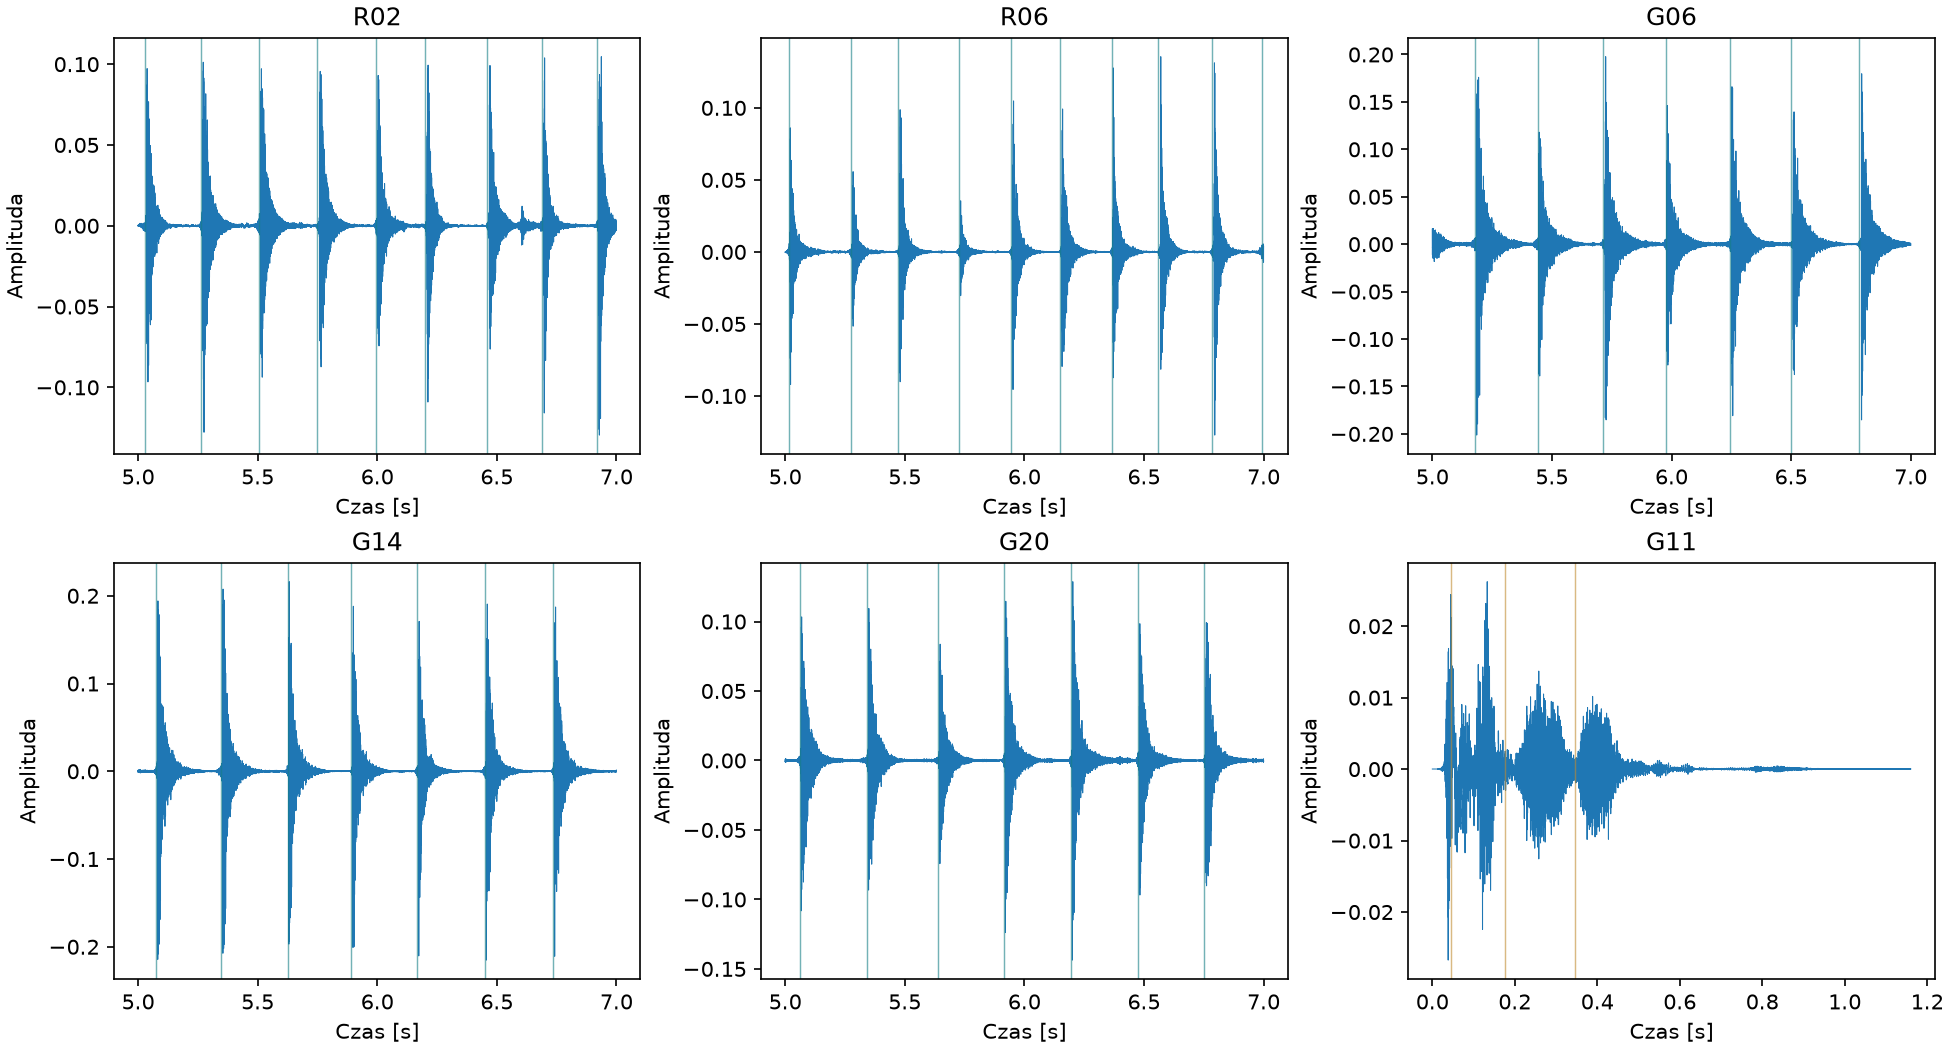

,recording_id,n_candidates,n_gap250,n_gap400,n_accepted,median_gap_s
0,R01,242,149,109,239,0.245
1,R02,128,74,58,126,0.245
2,R03,112,95,50,91,0.260
3,R04,89,85,43,77,0.290
4,R05,156,78,65,147,0.235
5,R06,168,78,72,163,0.225
6,R07,159,129,74,157,0.265
7,R08,158,156,66,157,0.315
8,R09,159,124,67,159,0.255
24,G01,100,98,43,96,0.290


rejection
attack contrast <12 dB                                                42
file edge                                                             23
file edge; next hit or edge before 150 ms                             12
attack contrast <12 dB; background                                     8
file edge; attack contrast <12 dB                                      7
next hit or edge before 150 ms                                         6
background                                                             6
attack contrast <12 dB; next hit or edge before 150 ms                 5
file shorter than 2 s; file edge; attack contrast <12 dB               4
file edge; attack contrast <12 dB; next hit or edge before 150 ms      3
attack contrast <12 dB; next hit or edge before 150 ms; background     2
file edge; background                                                  1
file edge; attack contrast <12 dB; background                          1
file shorter than 2 s; file edge; next hi

In [5]:
display(Image(filename=str(OUT / "figures/detector_review.png")))
display(recordings.loc[recordings.scope.eq("core"),["recording_id","n_candidates","n_gap250","n_gap400","n_accepted","median_gap_s"]].round(3))
display(candidates[candidates.accepted.eq(False)].rejection.value_counts().rename("Liczba"))

## 5. Co słychać w widmie i co zmienia stanowisko
Pik to mocno obecna częstotliwość drgań. Krzywa pokazuje rozkład energii po częstotliwościach. Wysokość znormalizowano, aby porównać kształt. Prawa część ogranicza porównanie do 4 podpór bez zmiany narzędzia. Różnica widma sama nie dowodzi, że jej przyczyną jest pęknięcie.

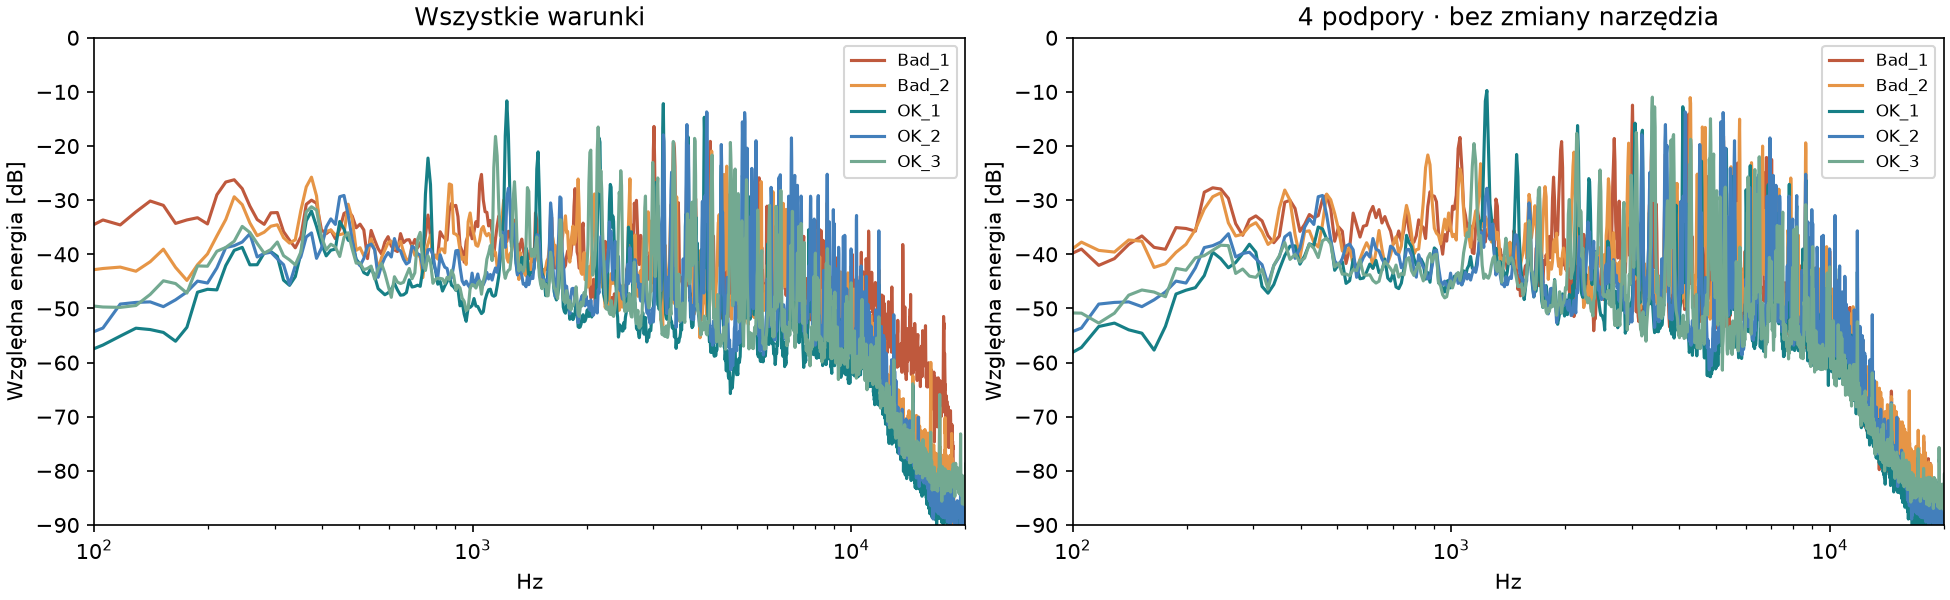

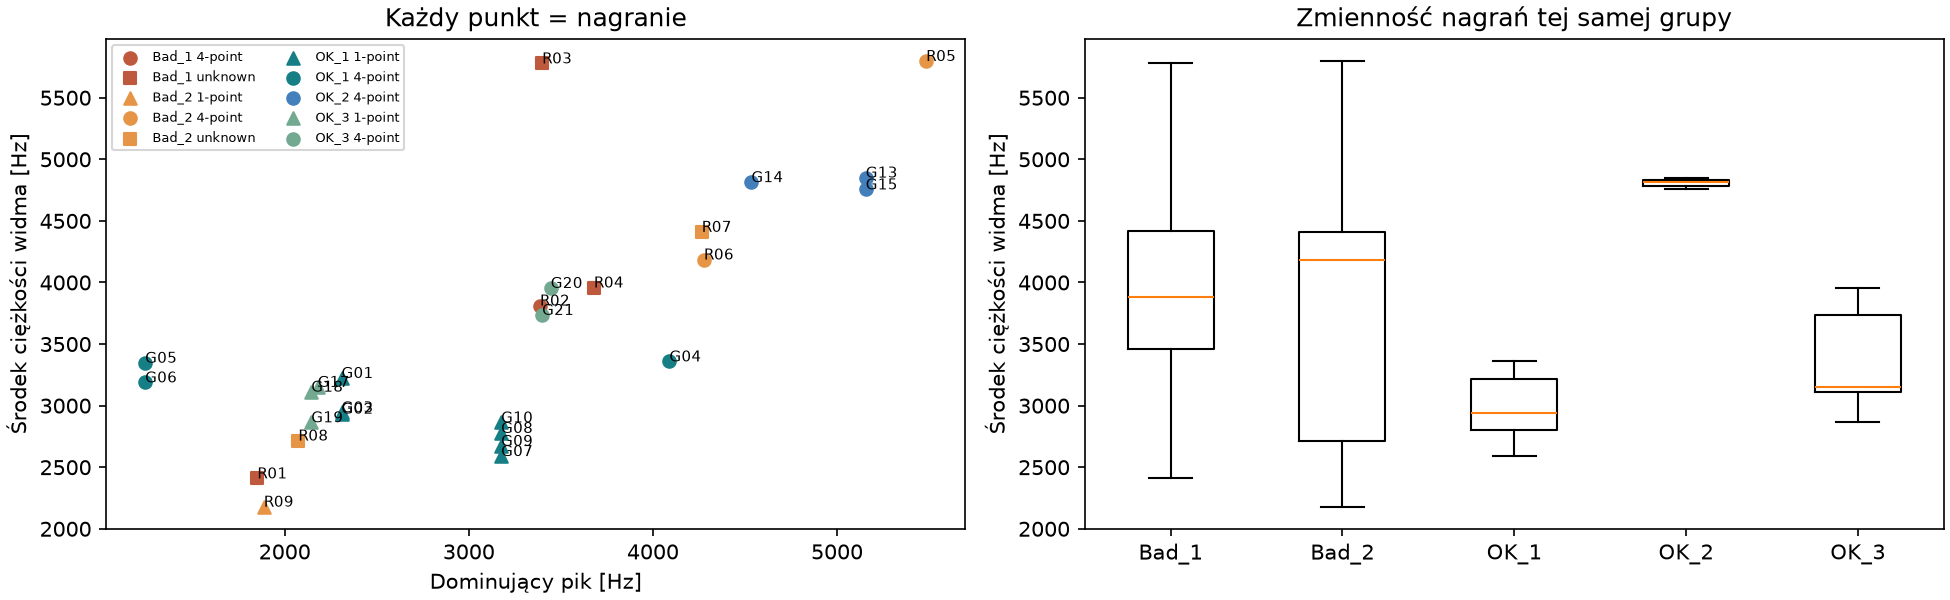

In [6]:
display(Image(filename=str(OUT / "figures/spectra.png")))
display(Image(filename=str(OUT / "figures/conditions.png")))

## 6. Co poprosić operatora
1. Krótki test z ulepszeniami wejścia wyłączonymi: 1 OK i 1 NOK, 10 s tła, 10 uderzeń co 2–3 s, 10 s tła.
2. Bezpośredni WAV PCM 48 kHz, ręczny stały gain, potwierdzone wejście mikrofonowe.
3. Jedno narzędzie i schemat podpór, 5 oznaczonych miejsc po 2 uderzenia, identycznie dla obu klas.
4. ID płytki i sesji, zdjęcie i rodzaj wady, typ płyty, temperatura, miejsce uderzenia oraz geometria mikrofonu.
5. Kolejne różne płytki oraz ~10 min tła. Potem sprawdzimy nową sesję bez zmiany modelu.

Przejdź do **03_modele_obu_paczek.ipynb**. Raport zbiorczy: `reports/runs/client-combined-20260929/START.html`.

In [7]:
from datetime import datetime, timezone
verification = dict(notebook="quality", finished_utc=datetime.now(timezone.utc).isoformat(), python=sys.executable)
(OUT / "last_run_quality.json").write_text(json.dumps(verification, indent=2))
print("GOTOWE — quality: wszystkie komórki zakończone.")

GOTOWE — quality: wszystkie komórki zakończone.
